In [ ]:
!pip install split-folders

In [ ]:
import os
#ดึงโฟลเดอร์ train val ชื่อ /Bark_runModel
# ลิงก์ WebDAV ดาวน์โหลดเฉพาะโฟลเดอร์ Bark_runModel
ku_download_url = "https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_runModel/?accept=zip"

# ดาวน์โหลดไฟล์ zip
!wget -O /content/Bark_runModel.zip "{ku_download_url}"

# สร้างโฟลเดอร์ปลายทาง
!mkdir -p /content/dataset/Plant/Bark_runModel

# แตกไฟล์ zip เข้าโฟลเดอร์ Bark_runModel โดยตรง
!unzip -q /content/Bark_runModel.zip -d /content/dataset/Plant/Bark_runModel/

# ตรวจสอบโฟลเดอร์และจำนวนคลาสที่แตกออกมา
print("✅ ดาวน์โหลดและแตกไฟล์เรียบร้อยแล้ว!")
!ls -lh /content/dataset/Plant/Bark_runModel

--2026-10-30 04:31:41--  https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_runModel/?accept=zip
Resolving kudrive.ku.ac.th (kudrive.ku.ac.th)... 158.108.219.93, 2406:3100:1010:101::93
Connecting to kudrive.ku.ac.th (kudrive.ku.ac.th)|158.108.219.93|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘/content/Bark_runModel.zip’

/content/Bark_runMo     [            <=>     ]   4.94G  16.5MB/s    in 5m 14s  

2026-10-30 04:36:56 (16.1 MB/s) - ‘/content/Bark_runModel.zip’ saved [5306816837]

✅ ดาวน์โหลดและแตกไฟล์เรียบร้อยแล้ว!
total 4.0K
drwxr-xr-x 17 root root 4.0K Oct 30 04:31 Bark_runModel


In [ ]:
import os
#ดึงโฟลเดอร์ test ชื่อ Bark_Test_53_Final
# วางลิงก์ WebDAV ที่คัดลอกมาจากปุ่มดาวน์โหลดของ Bark_Test_53_Final
ku_test_url = "https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_Test_53_Final/?accept=zip"

# ดาวน์โหลดไฟล์ zip ของชุด Test
!wget -O /content/Bark_Test_53_Final.zip "{ku_test_url}"

# สร้างโฟลเดอร์ปลายทาง
!mkdir -p /content/Bark_Test_53_Final

# แตกไฟล์ zip เข้าโฟลเดอร์ /content/Bark_Test_53_Final โดยตรง
!unzip -q /content/Bark_Test_53_Final.zip -d /content/Bark_Test_53_Final/

# ตรวจสอบรายชื่อทั้ง 15 สายพันธุ์ด้านใน
print("✅ ดาวน์โหลดและแตกไฟล์ Bark_Test_53_Final เรียบร้อยแล้ว!")
!ls -lh /content/Bark_Test_53_Final

--2026-10-30 04:37:54--  https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_Test_53_Final/?accept=zip
Resolving kudrive.ku.ac.th (kudrive.ku.ac.th)... 158.108.219.93, 2406:3100:1010:101::93
Connecting to kudrive.ku.ac.th (kudrive.ku.ac.th)|158.108.219.93|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘/content/Bark_Test_53_Final.zip’

/content/Bark_Test_     [          <=>       ] 535.60M  15.8MB/s    in 35s     

2026-10-30 04:38:30 (15.3 MB/s) - ‘/content/Bark_Test_53_Final.zip’ saved [561620555]

✅ ดาวน์โหลดและแตกไฟล์ Bark_Test_53_Final เรียบร้อยแล้ว!
total 4.0K
drwxr-xr-x 17 root root 4.0K Oct 30 04:37 Bark_Test_53_Final


In [ ]:
import os
import glob
import shutil
import pandas as pd
import splitfolders

# 1. กำหนด path โฟลเดอร์ต้นทาง
train_val_source_dir = '/content/dataset/Plant/Bark_runModel/Bark_runModel' # ที่มีภาพสำหรับทำ train/val
test_source_dir = '/content/Bark_Test_53_Final/Bark_Test_53_Final'               # โฟลเดอร์ test ที่มี 15 พันธุ์ พันธุ์ละ 53 ภาพ
split_dir = '/content/split_dataset'

# ลบโฟลเดอร์เก่าทิ้งก่อน (ถ้ามี)
!rm -rf {split_dir}
os.makedirs(split_dir, exist_ok=True)

# 2. แบ่ง Bark_runModel เป็น Train 247 และ Val 53 ภาพ
# ใช้ splitfolders.fixed กำหนด val=53 ภาพ ส่วนที่เหลือทั้งหมดจะกลายเป็น train (247 ภาพจาก 300 ภาพเดิม)
print("⚙️ กำลังแบ่งชุดข้อมูล Train (247) และ Val (53)...")
splitfolders.fixed(
    train_val_source_dir,
    output=split_dir,
    seed=42,
    fixed=(53,),
    oversample=False,
    group_prefix=None
)

# 3. นำโฟลเดอร์ Test จาก Bark_Test_53_Final มาวางไว้ที่ split_dataset/test
target_test_dir = os.path.join(split_dir, 'test')
if os.path.exists(target_test_dir):
    shutil.rmtree(target_test_dir)

print("⚙️ กำลังคัดลอกโฟลเดอร์ Test (15 พันธุ์ x 53 รูป) เข้ามาในระบบ...")
shutil.copytree(test_source_dir, target_test_dir)

print(f"✅ จัดโครงสร้าง Train/Val/Test เรียบร้อยแล้ว อยู่ที่: {split_dir}\n")

# 4. สร้างรายงานสรุปจำนวนภาพ (Dataset Split Report)
all_classes = set()
for sub in ['train', 'val', 'test']:
    sub_dir = os.path.join(split_dir, sub)
    if os.path.exists(sub_dir):
        all_classes.update([
            d for d in os.listdir(sub_dir)
            if os.path.isdir(os.path.join(sub_dir, d))
        ])

all_classes = sorted(list(all_classes))
report_data = []

for cls in all_classes:
    row = {'Class Name': cls}
    total_class_images = 0

    for sub in ['train', 'val', 'test']:
        folder_path = os.path.join(split_dir, sub, cls)

        if os.path.exists(folder_path):
            count = len([
                f for f in os.listdir(folder_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))
            ])
        else:
            count = 0

        row[sub.capitalize()] = count
        total_class_images += count

    row['Total'] = total_class_images
    report_data.append(row)

# สร้าง DataFrame
df_report = pd.DataFrame(report_data)

# คำนวณแถวสรุปผลรวมทั้งหมด (Total Row)
total_row = {'Class Name': 'Total'}
for col in df_report.columns:
    if col != 'Class Name':
        total_row[col] = df_report[col].sum()

df_report = pd.concat(
    [df_report, pd.DataFrame([total_row])],
    ignore_index=True
)

print("=" * 65)
print(" 📊 รายงานสรุปจำนวนภาพในแต่ละโฟลเดอร์ (Dataset Split Report)")
print("=" * 65)
display(df_report)

# 5. บันทึกไฟล์ CSV ลง Google Drive ในโฟลเดอร์ ConvN
from google.colab import drive

drive.mount('/content/drive')

# สร้างโฟลเดอร์ ConvN หากยังไม่มี
drive_folder = '/content/drive/MyDrive/ConvN'
os.makedirs(drive_folder, exist_ok=True)

# บันทึกไฟล์ CSV
report_csv_path = os.path.join(
    drive_folder,
    'dataset_split_report_final.csv'
)

df_report.to_csv(
    report_csv_path,
    index=False,
    encoding='utf-8-sig'
)

print(f"\n📁 บันทึกตารางรายงานเรียบร้อยแล้วที่: {report_csv_path}")

⚙️ กำลังแบ่งชุดข้อมูล Train (247) และ Val (53)...


Copying files: 4500 files [00:42, 104.68 files/s]


⚙️ กำลังคัดลอกโฟลเดอร์ Test (15 พันธุ์ x 53 รูป) เข้ามาในระบบ...
✅ จัดโครงสร้าง Train/Val/Test เรียบร้อยแล้ว อยู่ที่: /content/split_dataset

 📊 รายงานสรุปจำนวนภาพในแต่ละโฟลเดอร์ (Dataset Split Report)


,Class Name,Train,Val,Test,Total
0,Alstonia scholaris,247,53,53,353
1,Cassia fistula,247,53,53,353
2,Delonix regia,247,53,53,353
3,Dipterocarpus alatus Roxb,247,53,53,353
4,Lagerstroemia duperreana,247,53,53,353
5,Lagerstroemia loudonii,247,53,53,353
6,Lagerstroemia macrocarpa,247,53,53,353
7,Peltophorum dasyrhachis,247,53,53,353
8,Peltophorum pterocarpum,247,53,53,353
9,Pterocarpus indicus,247,53,53,353


Mounted at /content/drive

📁 บันทึกตารางรายงานเรียบร้อยแล้วที่: /content/drive/MyDrive/ConvN/dataset_split_report_final.csv


Found 3705 files belonging to 15 classes.
Found 795 files belonging to 15 classes.
Found 795 files belonging to 15 classes.

Classes (15): ['Alstonia scholaris', 'Cassia fistula', 'Delonix regia', 'Dipterocarpus alatus Roxb', 'Lagerstroemia duperreana', 'Lagerstroemia loudonii', 'Lagerstroemia macrocarpa', 'Peltophorum dasyrhachis', 'Peltophorum pterocarpum', 'Pterocarpus indicus', 'Pterocarpus macrocarpus', 'Streblus asper', 'Swietenia macrophylla', 'Tectona grandis', 'Triplaris cumingiana Fisch']
Train images: 3705
Validation images: 795
Test images: 795
Training seeds: [42, 123, 2026]

เริ่มเทรน ConvNeXt-Tiny | Seed 42
Found 3705 files belonging to 15 classes.
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.4934 - loss: 1.9484 — Val Macro-F1: 88.5410%
116/116 ━━━━━━━━━━━━━━━━━━━━ 114s 879ms/step - accuracy: 0.7109 - loss: 1.3853 - val_accuracy: 0.8855 - val_loss: 0.7048 - val_macro_f1: 0.8854
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.918

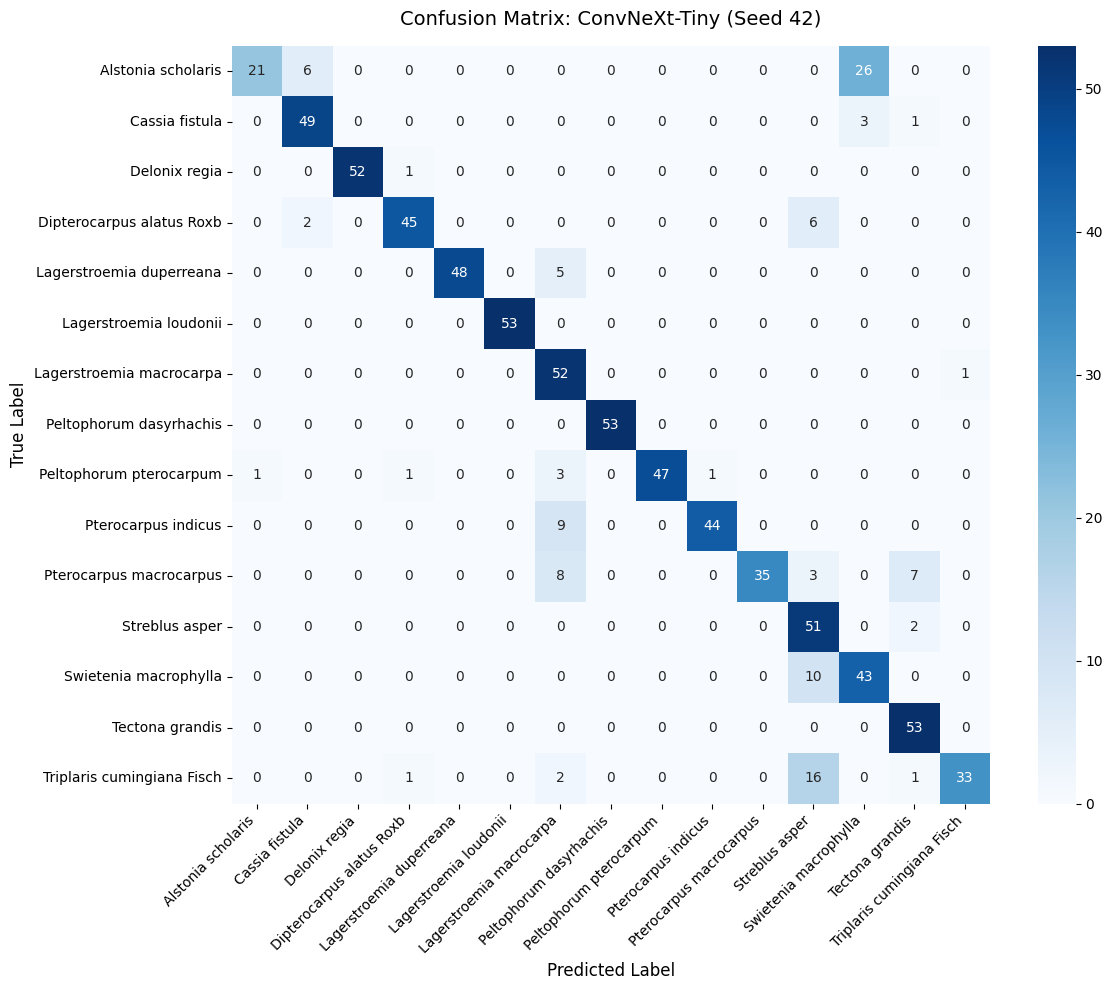

Seed 42 | Training time: 34.10 min (2046.12 sec)
Accuracy: 85.4088% | Macro-F1: 85.2712%
Macro-Precision: 89.1777% | Macro-Recall: 85.4088%
AUC: 0.9909 | MCC: 0.8466

เริ่มเทรน ConvNeXt-Tiny | Seed 123
Found 3705 files belonging to 15 classes.
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.4992 - loss: 1.9319 — Val Macro-F1: 89.3519%
116/116 ━━━━━━━━━━━━━━━━━━━━ 114s 879ms/step - accuracy: 0.7109 - loss: 1.3790 - val_accuracy: 0.8943 - val_loss: 0.7053 - val_macro_f1: 0.8935
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.8962 - loss: 0.6080 — Val Macro-F1: 93.2018%
116/116 ━━━━━━━━━━━━━━━━━━━━ 87s 750ms/step - accuracy: 0.9139 - loss: 0.5222 - val_accuracy: 0.9321 - val_loss: 0.4156 - val_macro_f1: 0.9320
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.9358 - loss: 0.3720 — Val Macro-F1: 95.2142%
116/116 ━━━━━━━━━━━━━━━━━━━━ 89s 767ms/step - accuracy: 0.9441 - loss: 0.3403 - val_accuracy: 0.9522 - val_loss: 0.3026 - val_macr

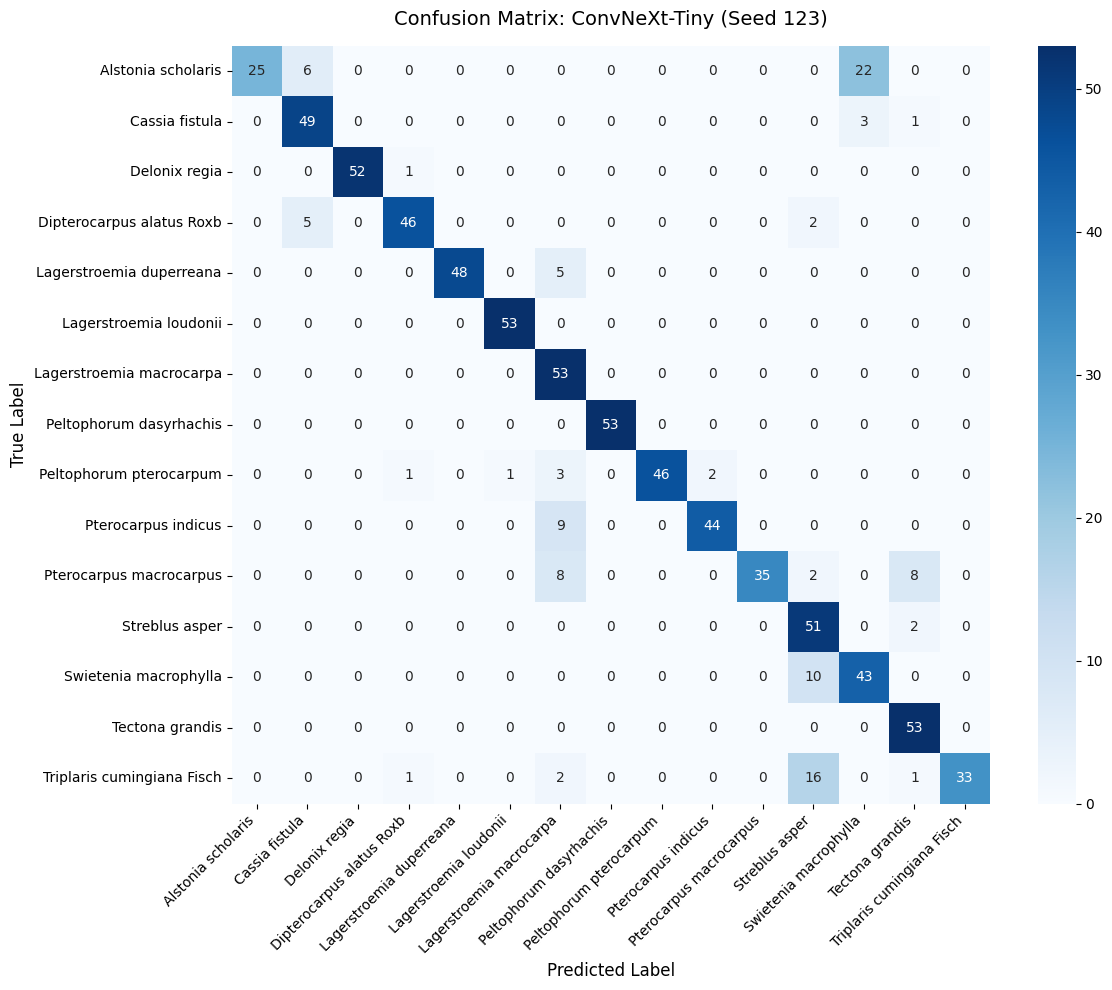

Seed 123 | Training time: 36.17 min (2170.47 sec)
Accuracy: 86.0377% | Macro-F1: 85.9345%
Macro-Precision: 89.5554% | Macro-Recall: 86.0377%
AUC: 0.9910 | MCC: 0.8530

เริ่มเทรน ConvNeXt-Tiny | Seed 2026
Found 3705 files belonging to 15 classes.
Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.5556 - loss: 1.8838 — Val Macro-F1: 90.2819%
116/116 ━━━━━━━━━━━━━━━━━━━━ 115s 893ms/step - accuracy: 0.7503 - loss: 1.3371 - val_accuracy: 0.9031 - val_loss: 0.6777 - val_macro_f1: 0.9028
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.9094 - loss: 0.5705 — Val Macro-F1: 93.6777%
116/116 ━━━━━━━━━━━━━━━━━━━━ 95s 818ms/step - accuracy: 0.9204 - loss: 0.5028 - val_accuracy: 0.9371 - val_loss: 0.4044 - val_macro_f1: 0.9368
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.9378 - loss: 0.3510 — Val Macro-F1: 95.7060%
116/116 ━━━━━━━━━━━━━━━━━━━━ 88s 755ms/step - accuracy: 0.9433 - loss: 0.3273 - val_accuracy: 0.9572 - val_loss: 0.2955 - val_ma

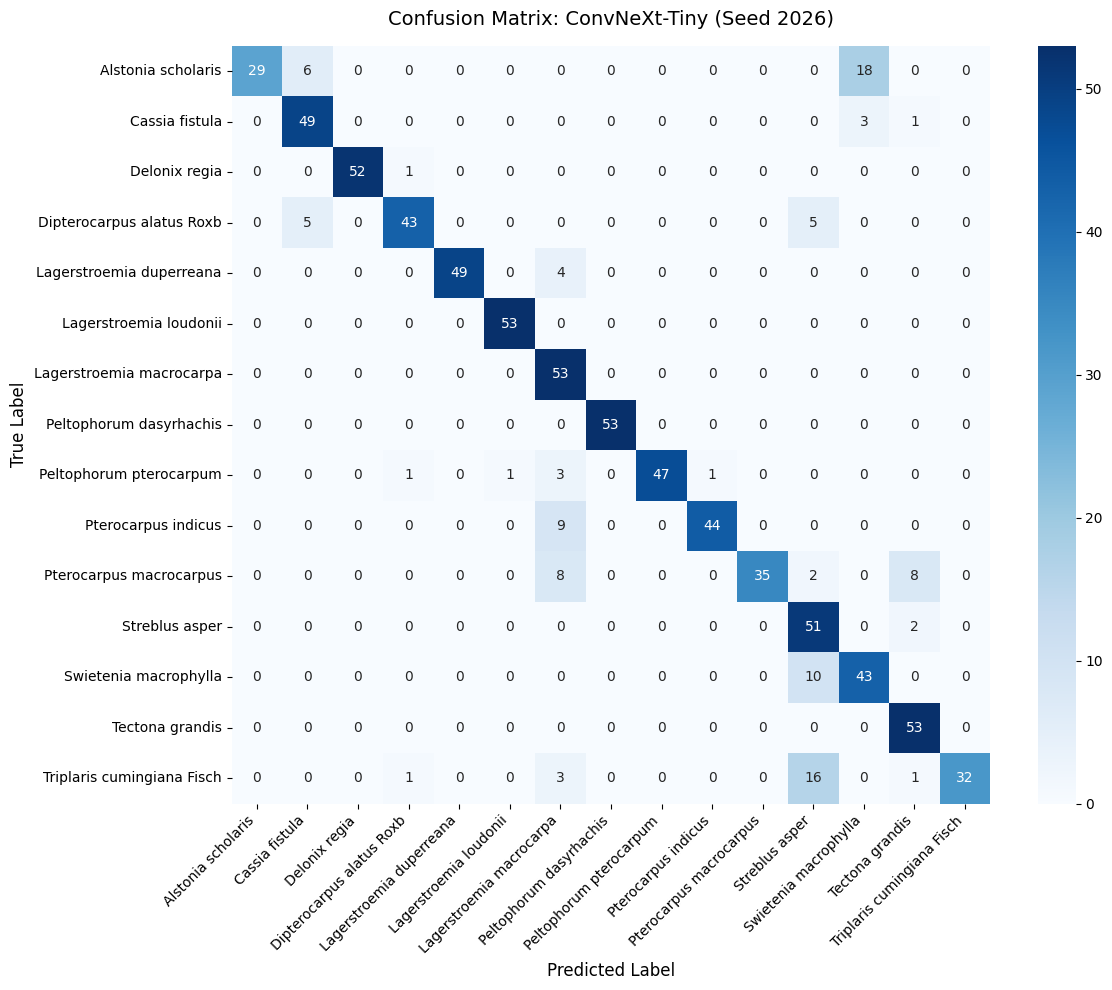

Seed 2026 | Training time: 34.39 min (2063.38 sec)
Accuracy: 86.2893% | Macro-F1: 86.3093%
Macro-Precision: 89.7841% | Macro-Recall: 86.2893%
AUC: 0.9907 | MCC: 0.8557


In [ ]:
import os
import time
import random
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from scipy.stats import binomtest, chi2
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)

split_dir = "split_dataset"
train_dir = os.path.join(split_dir, "train")
val_dir = os.path.join(split_dir, "val")
test_dir = os.path.join(split_dir, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
SEEDS = [42, 123, 2026]
AUTOTUNE = tf.data.AUTOTUNE

# ใช้ class order เดียวกันทุก split และทุก seed
train_ds_base = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False
)
CLASS_NAMES = train_ds_base.class_names
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 15, f"คาดหวัง 15 classes แต่พบ {NUM_CLASSES}"

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False, class_names=CLASS_NAMES
).prefetch(AUTOTUNE)
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False, class_names=CLASS_NAMES
)
test_file_paths = list(test_ds_raw.file_paths)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

# เก็บ label และลำดับ Image ID จากไฟล์ Test Set 795 ภาพ
test_labels_onehot = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_true = np.argmax(test_labels_onehot, axis=1)
assert len(test_file_paths) == len(y_true) == 795, (
    f"Test Set ต้องมี 795 ภาพ แต่พบ paths={len(test_file_paths)}, labels={len(y_true)}"
)
image_ids = [f"img{i:03d}" for i in range(1, len(test_file_paths) + 1)]
test_manifest = pd.DataFrame({
    "Image ID": image_ids,
    "File Name": [os.path.basename(p) for p in test_file_paths],
    "File Path": test_file_paths,
    "True Label": [CLASS_NAMES[i] for i in y_true],
    "True Label Index": y_true
})
test_manifest.to_csv(
    "/content/test_manifest_convnext.csv", index=False, encoding="utf-8-sig"
)

print(f"\nClasses ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Train images: {sum(1 for c in CLASS_NAMES for f in os.listdir(os.path.join(train_dir, c)) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff')))}")
print(f"Validation images: {sum(1 for c in CLASS_NAMES for f in os.listdir(os.path.join(val_dir, c)) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff')))}")
print(f"Test images: {len(y_true)}")
print("Training seeds:", SEEDS)

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


# เพิ่มเฉพาะส่วนคำนวณ Val Macro-F1 ทุก Epoch
class ValidationMacroF1Callback(tf.keras.callbacks.Callback):
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds
        self.y_true = np.concatenate([
            np.argmax(labels.numpy(), axis=1)
            for _, labels in val_ds
        ])
        self.val_macro_f1 = []

    def on_epoch_end(self, epoch, logs=None):
        y_pred_prob = self.model.predict(self.val_ds, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        score = f1_score(
            self.y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
        self.val_macro_f1.append(score)

        if logs is not None:
            logs["val_macro_f1"] = score

        print(f" — Val Macro-F1: {score * 100:.4f}%")


def build_convnext_tiny():
    # คง architecture เดิม: ConvNeXt-Tiny ImageNet, freeze backbone, Dense 15 classes
    base_convnext = tf.keras.applications.ConvNeXtTiny(
        include_top=True,
        include_preprocessing=True,
        weights="imagenet",
        input_tensor=None,
        input_shape=None,
        pooling=None,
        classes=1000,
        classifier_activation="softmax"
    )
    for layer in base_convnext.layers:
        layer.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3), name="input_224")
    feature_extractor = tf.keras.Model(
        inputs=base_convnext.input,
        outputs=base_convnext.layers[-2].output,
        name="convnext_tiny_feature_extractor"
    )
    features = feature_extractor(inputs)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax", name="bark_predictions"
    )(features)
    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"ConvNeXtTiny_Bark_Classifier_{NUM_CLASSES}Classes"
    )
    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def make_train_dataset(seed):
    # สร้าง dataset ใหม่ต่อ seed เพื่อให้ลำดับการ shuffle เปลี่ยนตาม seed
    ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="categorical", shuffle=True, seed=seed,
        class_names=CLASS_NAMES
    )
    return ds.prefetch(AUTOTUNE)

# ผลลัพธ์ทั้งหมดเก็บแยกตาม seed และนำไปสรุปรวมใน cell ถัดไป
RESULTS = {}
for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"เริ่มเทรน ConvNeXt-Tiny | Seed {seed}")
    print("=" * 80)
    tf.keras.backend.clear_session()
    set_seed(seed)
    train_ds = make_train_dataset(seed)
    model_convnext = build_convnext_tiny()

    log_csv_path = f"/content/training_log_convnext_tiny_15classes_seed{seed}.csv"
    csv_logger = tf.keras.callbacks.CSVLogger(log_csv_path, separator=",", append=False)

    # เพิ่ม Callback สำหรับ Val Macro-F1
    val_macro_f1_callback = ValidationMacroF1Callback(val_ds)

    start_time = time.time()
    history = model_convnext.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[val_macro_f1_callback, csv_logger],
        verbose=1
    )
    training_time = time.time() - start_time

    # หา Epoch ที่มี Val Macro-F1 สูงที่สุด
    best_epoch = int(np.argmax(val_macro_f1_callback.val_macro_f1)) + 1
    best_val_macro_f1 = float(max(val_macro_f1_callback.val_macro_f1))

    print(f"\nBest Epoch: {best_epoch}")
    print(f"Best Val Macro-F1: {best_val_macro_f1 * 100:.4f}%")

    y_pred_prob = model_convnext.predict(test_ds, verbose=1)
    y_pred = np.argmax(y_pred_prob, axis=1)
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    auc = roc_auc_score(test_labels_onehot, y_pred_prob, multi_class="ovr", average="macro")
    mcc = matthews_corrcoef(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    report_dict = classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0
    )
    report_df = pd.DataFrame(report_dict).T

    RESULTS[seed] = {
        "history": history,
        "training_time": training_time,
        "y_pred": y_pred,
        "y_pred_prob": y_pred_prob,
        "acc": acc,
        "macro_f1": macro_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "auc": auc,
        "mcc": mcc,
        "cm": cm,
        "report": report_df,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_val_macro_f1,
        "val_macro_f1": val_macro_f1_callback.val_macro_f1,
        "history_df": pd.DataFrame({
            "Epoch": range(1, len(history.history["loss"]) + 1),
            "Train Loss": history.history["loss"],
            "Train Accuracy": history.history["accuracy"],
            "Val Loss": history.history["val_loss"],
            "Val Accuracy": history.history["val_accuracy"],
            "Val Macro-F1": val_macro_f1_callback.val_macro_f1
        })
    }

    # Confusion Matrix แยกแต่ละ seed: CSV และรูป PNG
    seed_dir = f"/content/convnext_results/seed{seed}"
    os.makedirs(seed_dir, exist_ok=True)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).rename_axis(
        "True Label"
    ).to_csv(f"{seed_dir}/confusion_matrix_seed{seed}.csv", encoding="utf-8-sig")
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=True)
    plt.title(f"Confusion Matrix: ConvNeXt-Tiny (Seed {seed})", fontsize=14, pad=15)
    plt.ylabel("True Label", fontsize=12)
    plt.xlabel("Predicted Label", fontsize=12)
    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{seed_dir}/confusion_matrix_seed{seed}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    # Precision / Recall / F-score รายคลาสและแต่ละ seed
    per_class = report_df.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]].copy()
    per_class.index.name = "Class"
    per_class.to_csv(f"{seed_dir}/per_class_precision_recall_f1_seed{seed}.csv",
                     encoding="utf-8-sig")

    # Prediction รายภาพสำหรับตรวจสอบและ McNemar's test
    pred_df = test_manifest[["Image ID", "File Name", "True Label"]].copy()
    pred_df[f"ConvNeXt-Tiny Prediction Seed {seed}"] = [CLASS_NAMES[i] for i in y_pred]
    pred_df[f"ConvNeXt-Tiny Prediction Index Seed {seed}"] = y_pred
    pred_df.to_csv(f"{seed_dir}/predictions_test795_seed{seed}.csv",
                   index=False, encoding="utf-8-sig")

    # เก็บตัวแปรชื่อเดิมจากรอบ Seed 42 เพื่อให้ไฟล์ผลลัพธ์เดิมยังใช้ได้
    if seed == 42:
        model = model_convnext
        acc_42, macro_f1_42, auc_42, mcc_42 = acc, macro_f1, auc, mcc
        cm_42, history_42, training_time_42 = cm.copy(), history, training_time
        y_pred_42, y_pred_prob_42 = y_pred.copy(), y_pred_prob.copy()
        df_history_42 = RESULTS[seed]["history_df"].copy()
        csv_logger_path_42 = log_csv_path

    print(f"Seed {seed} | Training time: {training_time/60:.2f} min ({training_time:.2f} sec)")
    print(f"Accuracy: {acc*100:.4f}% | Macro-F1: {macro_f1*100:.4f}%")
    print(f"Macro-Precision: {macro_precision*100:.4f}% | Macro-Recall: {macro_recall*100:.4f}%")
    print(f"AUC: {auc:.4f} | MCC: {mcc:.4f}")

# คืนค่าชื่อตัวแปรเดิมจาก seed 42 เพื่อรองรับ output cell เดิม
history = history_42
training_time = training_time_42
acc = acc_42
macro_f1 = macro_f1_42
auc = auc_42
mcc = mcc_42
cm = cm_42
y_pred = y_pred_42
y_pred_prob = y_pred_prob_42

In [ ]:
# คำนวณค่าที่ขาดจากโมเดล Seed 2026 ที่ยังอยู่ในหน่วยความจำ
test_loss_2026, _ = model_convnext.evaluate(test_ds, verbose=0)

start = time.time()
_ = model_convnext.predict(test_ds, verbose=0)
inference_2026 = time.time() - start

print("Seed 123")
print("Test Loss:", test_loss_2026)
print("Test Inference (sec):", inference_2026)
print("Parameters (M):", model_convnext.count_params() / 1e6)

Seed 123
Test Loss: 0.46957555413246155
Test Inference (sec): 9.318222522735596
Parameters (M): 27.831663


In [ ]:
import os
import itertools
import shutil
import pandas as pd
import numpy as np
from scipy.stats import binomtest, chi2

drive_path = "/content/drive/MyDrive"
os.makedirs(drive_path, exist_ok=True)
results_dir = "/content/convnext_results"
os.makedirs(results_dir, exist_ok=True)

# คงชื่อไฟล์ Excel เดิมและชีตเดิมไว้
combined_excel_file = "bark_classification_all_models_11classes.xlsx"
full_excel_path = os.path.join(drive_path, combined_excel_file)

# ---------- 1. ตารางผลราย seed ----------
seed_rows = []
for seed in SEEDS:
    R = RESULTS[seed]
    seed_rows.append({
        "Model": "ConvNeXt-Tiny",
        "Seed": seed,
        "Test Images": len(y_true),
        "Macro-F1 (%)": R["macro_f1"] * 100,
        "Accuracy (%)": R["acc"] * 100,
        "Macro-Precision (%)": R["macro_precision"] * 100,
        "Macro-Recall (%)": R["macro_recall"] * 100,
        "AUC": R["auc"],
        "MCC": R["mcc"],
        "Training Time (minutes)": R["training_time"] / 60,
        "Training Time (seconds)": R["training_time"]
    })
df_seed_results = pd.DataFrame(seed_rows)
df_seed_results.to_csv(
    f"{results_dir}/06_results_per_seed.csv", index=False, encoding="utf-8-sig"
)
display(df_seed_results.round(4))

# ---------- 2. Mean / SD ข้าม 3 seeds (sample SD, ddof=1) ----------
metric_cols = [
    "Macro-F1 (%)", "Accuracy (%)", "Macro-Precision (%)",
    "Macro-Recall (%)", "AUC", "MCC"
]
mean_sd_rows = []
for metric in metric_cols:
    vals = df_seed_results[metric].astype(float)
    mean_sd_rows.append({
        "Metric": metric,
        "Mean": vals.mean(),
        "SD": vals.std(ddof=1),
        "Seed 42": vals.iloc[0],
        "Seed 123": vals.iloc[1],
        "Seed 2026": vals.iloc[2]
    })
df_mean_sd = pd.DataFrame(mean_sd_rows)
df_mean_sd.to_csv(
    f"{results_dir}/07_mean_sd.csv", index=False, encoding="utf-8-sig"
)
display(df_mean_sd.round(4))

# ---------- 3. Precision / Recall / F-score ทุกคลาสและทุก seed ----------
per_class_rows = []
for seed in SEEDS:
    report = RESULTS[seed]["report"]
    for class_name in CLASS_NAMES:
        per_class_rows.append({
            "Seed": seed,
            "Class": class_name,
            "Precision (%)": float(report.loc[class_name, "precision"]) * 100,
            "Recall (%)": float(report.loc[class_name, "recall"]) * 100,
            "F-score (%)": float(report.loc[class_name, "f1-score"]) * 100,
            "Support": int(report.loc[class_name, "support"])
        })
df_per_class_all = pd.DataFrame(per_class_rows)
df_per_class_all.to_csv(
    f"{results_dir}/08_per_class_precision_recall_fscore_all_seeds.csv",
    index=False, encoding="utf-8-sig"
)

# ---------- 4. Confusion matrix รวมทุก seed เป็น CSV แยก ----------
cm_long_rows = []
for seed in SEEDS:
    cm_df = pd.DataFrame(RESULTS[seed]["cm"], index=CLASS_NAMES, columns=CLASS_NAMES)
    cm_df.index.name = "True Label"
    cm_df.to_csv(
        f"{results_dir}/seed{seed}/confusion_matrix_seed{seed}.csv",
        encoding="utf-8-sig"
    )
    for i, true_name in enumerate(CLASS_NAMES):
        for j, pred_name in enumerate(CLASS_NAMES):
            cm_long_rows.append({
                "Seed": seed, "True Label": true_name,
                "Predicted Label": pred_name, "Count": int(RESULTS[seed]["cm"][i, j])
            })
pd.DataFrame(cm_long_rows).to_csv(
    f"{results_dir}/10_confusion_matrices_all_seeds.csv",
    index=False, encoding="utf-8-sig"
)

# ---------- 5. Predictions 795 ภาพ: 1 CSV ต่อ seed + CSV รวม ----------
prediction_frames = []
for seed in SEEDS:
    R = RESULTS[seed]
    pred_df = test_manifest[["Image ID", "File Name", "True Label"]].copy()
    pred_df[f"ConvNeXt-Tiny Prediction Seed {seed}"] = [
        CLASS_NAMES[i] for i in R["y_pred"]
    ]
    pred_df[f"ConvNeXt-Tiny Prediction Index Seed {seed}"] = R["y_pred"]
    pred_df.to_csv(
        f"{results_dir}/seed{seed}/predictions_test795_seed{seed}.csv",
        index=False, encoding="utf-8-sig"
    )
    pred_for_merge = pred_df[[
        "Image ID", "True Label", f"ConvNeXt-Tiny Prediction Seed {seed}"
    ]]
    prediction_frames.append(pred_for_merge)
pred_all = prediction_frames[0]
for frame in prediction_frames[1:]:
    pred_all = pred_all.merge(frame, on=["Image ID", "True Label"], how="inner", validate="one_to_one")
assert len(pred_all) == 795
pred_all.to_csv(
    f"{results_dir}/09_predictions_all_seeds_test795.csv",
    index=False, encoding="utf-8-sig"
)
test_manifest.to_csv(
    f"{results_dir}/test_manifest_795.csv", index=False, encoding="utf-8-sig"
)

# ---------- 6. McNemar's test ระหว่างแต่ละคู่ seed บน Test Set เดียวกัน ----------
def mcnemar_pair(seed_a, seed_b):
    pred_a = RESULTS[seed_a]["y_pred"]
    pred_b = RESULTS[seed_b]["y_pred"]
    correct_a = pred_a == y_true
    correct_b = pred_b == y_true
    a = int(np.sum(correct_a & correct_b))       # ทั้งคู่ถูก
    b = int(np.sum(correct_a & ~correct_b))      # A ถูก B ผิด
    c = int(np.sum(~correct_a & correct_b))      # A ผิด B ถูก
    d = int(np.sum(~correct_a & ~correct_b))     # ทั้งคู่ผิด
    discordant = b + c
    if discordant == 0:
        p_exact = 1.0
        chi2_cc = 0.0
        p_chi2 = 1.0
        statistic = 0.0
        test_used = "No discordant pairs"
    else:
        p_exact = float(binomtest(min(b, c), n=discordant, p=0.5, alternative="two-sided").pvalue)
        chi2_cc = (max(0, abs(b - c) - 1) ** 2) / discordant
        p_chi2 = float(chi2.sf(chi2_cc, df=1))
        if discordant < 25:
            statistic = float(min(b, c))
            p_value = p_exact
            test_used = "Exact binomial"
        else:
            statistic = float(chi2_cc)
            p_value = p_chi2
            test_used = "Chi-square with continuity correction"
        return {
            "Comparison": "Between seeds (same ConvNeXt-Tiny model)",
            "Seed A": seed_a, "Seed B": seed_b, "n": len(y_true),
            "Both correct (a)": a, "A correct / B wrong (b)": b,
            "A wrong / B correct (c)": c, "Both wrong (d)": d,
            "Discordant (b+c)": discordant,
            "Accuracy A (%)": float(np.mean(correct_a) * 100),
            "Accuracy B (%)": float(np.mean(correct_b) * 100),
            "Test used": test_used, "Statistic": statistic,
            "p-value": p_value, "p (exact binomial)": p_exact,
            "Chi-square (cc)": chi2_cc, "p (chi-square)": p_chi2,
            "Significant (alpha=0.05)": bool(p_value < 0.05)
        }
    return {
        "Comparison": "Between seeds (same ConvNeXt-Tiny model)",
        "Seed A": seed_a, "Seed B": seed_b, "n": len(y_true),
        "Both correct (a)": a, "A correct / B wrong (b)": b,
        "A wrong / B correct (c)": c, "Both wrong (d)": d,
        "Discordant (b+c)": discordant,
        "Accuracy A (%)": float(np.mean(correct_a) * 100),
        "Accuracy B (%)": float(np.mean(correct_b) * 100),
        "Test used": test_used, "Statistic": statistic,
        "p-value": p_exact, "p (exact binomial)": p_exact,
        "Chi-square (cc)": chi2_cc, "p (chi-square)": p_chi2,
        "Significant (alpha=0.05)": False
    }

df_mcnemar = pd.DataFrame([
    mcnemar_pair(a, b) for a, b in itertools.combinations(SEEDS, 2)
])
df_mcnemar.to_csv(
    f"{results_dir}/11_mcnemar_between_seeds_test795.csv",
    index=False, encoding="utf-8-sig"
)
display(df_mcnemar)

# ---------- 7. คงไฟล์ผลลัพธ์เดิมสำหรับ Seed 42 ----------
df_history = df_history_42.copy()
df_test_metrics = pd.DataFrame({
    "Model": ["ConvNeXt-Tiny"] * 6,
    "Metric": [
        "Training Time (minutes)", "Training Time (seconds)",
        "Accuracy", "Macro-F1 Score", "AUC", "MCC"
    ],
    "Value": [
        round(training_time_42 / 60, 2), round(training_time_42, 2),
        round(acc_42, 4), round(macro_f1_42, 4),
        round(auc_42, 4), round(mcc_42, 4)
    ]
})
df_cm = pd.DataFrame(cm_42, index=CLASS_NAMES, columns=CLASS_NAMES)

total_params = model.count_params()
trainable_params = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
non_trainable_params = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
hyperparameters_table = [
    {"Hyperparameter": "Base Model", "Values": "ConvNeXt-Tiny"},
    {"Hyperparameter": "Weights", "Values": "ImageNet"},
    {"Hyperparameter": "Include Preprocessing", "Values": "True"},
    {"Hyperparameter": "Optimizer", "Values": "Adam (Keras default learning rate)"},
    {"Hyperparameter": "Loss Function", "Values": "Categorical Crossentropy"},
    {"Hyperparameter": "Input Shape", "Values": "224 x 224 x 3"},
    {"Hyperparameter": "No. of Dense Layers", "Values": f"1 (Dense {NUM_CLASSES} units)"},
    {"Hyperparameter": "Activation function", "Values": "Softmax"},
    {"Hyperparameter": "Batch Size", "Values": str(BATCH_SIZE)},
    {"Hyperparameter": "Epochs", "Values": str(EPOCHS)},
    {"Hyperparameter": "Data Split", "Values": "Train 247 / Val 53 per class; Test 53 per class"},
    {"Hyperparameter": "Random Seed (legacy result)", "Values": "42"},
    {"Hyperparameter": "Training Seeds", "Values": ", ".join(map(str, SEEDS))},
    {"Hyperparameter": "Total parameters", "Values": f"{total_params:,}"},
    {"Hyperparameter": "Trainable Parameters", "Values": f"{trainable_params:,}"},
    {"Hyperparameter": "Non-Trainable Parameters", "Values": f"{non_trainable_params:,}"}
]
df_params = pd.DataFrame(hyperparameters_table)

# CSV เดิมยังคงเขียนสำหรับผล Seed 42
df_history.to_csv(
    "/content/training_log_convnext_tiny_15classes.csv",
    index=False, encoding="utf-8-sig"
)
df_test_metrics.to_csv(
    os.path.join(drive_path, "test_metrics_convnext_tiny_15classes.csv"),
    index=False, encoding="utf-8-sig"
)
df_params.to_csv(
    os.path.join(drive_path, "hyperparameter_settings_for_ConvNeXtTiny_15classes.csv"),
    index=False, encoding="utf-8-sig"
)

# Excel เดิม: คงชื่อชีตเดิม และเพิ่มชีตผล multiseed
write_mode = "a" if os.path.exists(full_excel_path) else "w"
writer_kwargs = {"engine": "openpyxl"}
if write_mode == "a":
    writer_kwargs["mode"] = "a"
    writer_kwargs["if_sheet_exists"] = "replace"

with pd.ExcelWriter(full_excel_path, **writer_kwargs) as writer:
    df_history.to_excel(writer, sheet_name="ConvNeXt_History", index=False)
    df_test_metrics.to_excel(writer, sheet_name="ConvNeXt_Metrics", index=False)
    df_cm.to_excel(writer, sheet_name="ConvNeXt_ConfusionMatrix")
    df_params.to_excel(writer, sheet_name="ConvNeXt_Hyperparameters", index=False)
    df_seed_results.to_excel(writer, sheet_name="ConvNeXt_PerSeed", index=False)
    df_mean_sd.to_excel(writer, sheet_name="ConvNeXt_MeanSD", index=False)
    df_per_class_all.to_excel(writer, sheet_name="ConvNeXt_PerClass", index=False)
    pred_all.to_excel(writer, sheet_name="ConvNeXt_Predictions", index=False)
    df_mcnemar.to_excel(writer, sheet_name="ConvNeXt_McNemar", index=False)
    test_manifest.to_excel(writer, sheet_name="ConvNeXt_TestManifest", index=False)
    for seed in SEEDS:
        pd.DataFrame(RESULTS[seed]["cm"], index=CLASS_NAMES, columns=CLASS_NAMES).to_excel(
            writer, sheet_name=f"CM_seed{seed}"
        )
        RESULTS[seed]["report"].to_excel(writer, sheet_name=f"Report_seed{seed}")
        RESULTS[seed]["history_df"].to_excel(writer, sheet_name=f"History_seed{seed}", index=False)

# สำเนาผลลัพธ์ทั้งหมดขึ้น Google Drive (ไม่แก้ไขชุดข้อมูลต้นทาง)
drive_results_dir = os.path.join(drive_path, "ConvNeXt_Tiny_MultiSeed_Results")
shutil.copytree(results_dir, drive_results_dir, dirs_exist_ok=True)
print("=" * 75)
print("บันทึกผล ConvNeXt-Tiny × 3 seeds เสร็จแล้ว")
print(f"Excel เดิม + ชีตใหม่: {full_excel_path}")
print(f"CSV/CM/predictions/McNemar: {drive_results_dir}")
print("McNemar เปรียบเทียบผลทำนายแบบจับคู่จาก Test Set เดียวกัน 795 ภาพ ระหว่าง seed ทุกคู่")
print("=" * 75)
